# AquaSentinel AI — LSTM Autoencoder
Train a deep-learning anomaly detector on the simulated Net3 sensor dataset. Outputs are demonstrations on simulated data, not real-world validation. Run from the project root.

In [28]:
from pathlib import Path
import os

ROOT = Path.cwd()

# If Jupyter starts inside the notebooks folder, move to project root
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

os.chdir(ROOT)

DATA = ROOT / "data" / "processed" / "sensors.parquet"
MODEL_DIR = ROOT / "artifacts" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

METRICS_DIR = ROOT / "artifacts" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Dataset exists:", DATA.exists())

Project root: C:\Users\v\Projects\AquaSentinel-AI
Dataset exists: True


In [29]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
import joblib

SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA=Path('data/processed/sensors.parquet')
MODEL_DIR=Path('artifacts/models'); MODEL_DIR.mkdir(parents=True,exist_ok=True)
METRICS_DIR=Path('artifacts/metrics'); METRICS_DIR.mkdir(parents=True,exist_ok=True)
if not DATA.exists(): raise FileNotFoundError('Run python scripts/generate_dataset.py --quick from project root first.')
df=pd.read_parquet(DATA)
print('Shape:',df.shape,'Columns:',df.columns.tolist())
display(df.head())

Shape: (6984, 6) Columns: ['time_s', 'scenario_id', 'scenario_type', 'sensor_id', 'kind', 'value']


,time_s,scenario_id,scenario_type,sensor_id,kind,value
0,0,normal_00,normal,10,pressure,-0.450073
1,0,normal_00,normal,107,pressure,38.046030
2,0,normal_00,normal,197,pressure,37.508722
3,0,normal_00,normal,120,pressure,47.280854
4,0,normal_00,normal,195,pressure,39.842851


In [30]:
def find_col(cols, candidates):
    low={str(c).lower():c for c in cols}
    for x in candidates:
        if x in low: return low[x]
    for c in cols:
        if any(x in str(c).lower() for x in candidates): return c
    return None

val=find_col(df.columns,['value','reading','measurement','sensor_value','pressure','flowrate','flow'])
time=find_col(df.columns,['timestamp','time','time_seconds','step','timestep'])
sensor=find_col(df.columns,['sensor_id','sensor','node_id','link_id','element_id','name'])
label=find_col(df.columns,['label','is_leak','target','anomaly'])
print('Detected columns:',{'value':val,'time':time,'sensor':sensor,'label':label})
if val:
    tmp=df.copy()
    tmp[val]=pd.to_numeric(tmp[val],errors='coerce')
    if time is None: tmp['_time']=np.arange(len(tmp)); time='_time'
    if sensor is None: tmp['_sensor']='sensor_0'; sensor='_sensor'
    wide=tmp.pivot_table(index=time,columns=sensor,values=val,aggfunc='mean').sort_index()
    X=wide
else:
    numeric=df.select_dtypes(include=np.number).columns.tolist()
    if label in numeric: numeric.remove(label)
    if not numeric: raise ValueError('No numeric sensor value column found; inspect the printed columns and adjust detection.')
    X=df[numeric].copy()
X=X.replace([np.inf,-np.inf],np.nan).interpolate(limit_direction='both').ffill().bfill().fillna(0)
if len(X)<8: raise ValueError(f'Need at least 8 rows; found {len(X)}. Generate non-quick dataset.')
feature_names=[str(c) for c in X.columns]
scaler=StandardScaler()
split=max(1,int(len(X)*0.7)); scaler.fit(X.iloc[:split])
scaled=scaler.transform(X).astype('float32')
WINDOW=12
if len(scaled)<WINDOW: WINDOW=max(2,len(scaled)//2)
windows=np.stack([scaled[i-WINDOW:i] for i in range(WINDOW,len(scaled)+1)])
cut=max(1,int(len(windows)*0.7))
train=torch.tensor(windows[:cut],dtype=torch.float32)
valid=torch.tensor(windows[cut:] if cut<len(windows) else windows[-1:],dtype=torch.float32)
print('Window tensor:',windows.shape,'Device:',DEVICE)

Detected columns: {'value': 'value', 'time': 'time_s', 'sensor': 'sensor_id', 'label': None}
Window tensor: (86, 12, 22) Device: cpu


Epoch 1/10 loss=0.721421
Epoch 2/10 loss=0.696966
Epoch 3/10 loss=0.716446
Epoch 4/10 loss=0.674733
Epoch 5/10 loss=0.634832
Epoch 6/10 loss=0.614340
Epoch 7/10 loss=0.586211
Epoch 8/10 loss=0.539037
Epoch 9/10 loss=0.526308
Epoch 10/10 loss=0.479666


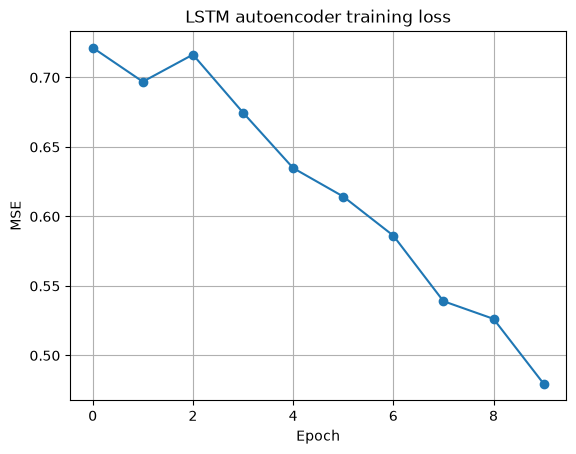

In [31]:
class LSTMAutoencoder(nn.Module):
    def __init__(self,n_features,hidden=32):
        super().__init__()
        self.encoder=nn.LSTM(n_features,hidden,batch_first=True)
        self.decoder=nn.LSTM(hidden,hidden,batch_first=True)
        self.output=nn.Linear(hidden,n_features)
    def forward(self,x):
        _,(h,_)=self.encoder(x)
        context=h[-1].unsqueeze(1).repeat(1,x.size(1),1)
        y,_=self.decoder(context)
        return self.output(y)

model=LSTMAutoencoder(train.shape[-1]).to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
loss_fn=nn.MSELoss()
loader=DataLoader(TensorDataset(train),batch_size=min(16,len(train)),shuffle=True)
EPOCHS=10
history=[]
for epoch in range(EPOCHS):
    model.train(); losses=[]
    for (batch,) in loader:
        batch=batch.to(DEVICE); optimizer.zero_grad()
        loss=loss_fn(model(batch),batch); loss.backward(); optimizer.step()
        losses.append(loss.item())
    history.append(float(np.mean(losses)))
    print(f'Epoch {epoch+1}/{EPOCHS} loss={history[-1]:.6f}')
plt.plot(history,marker='o'); plt.title('LSTM autoencoder training loss'); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.grid(True); plt.show()

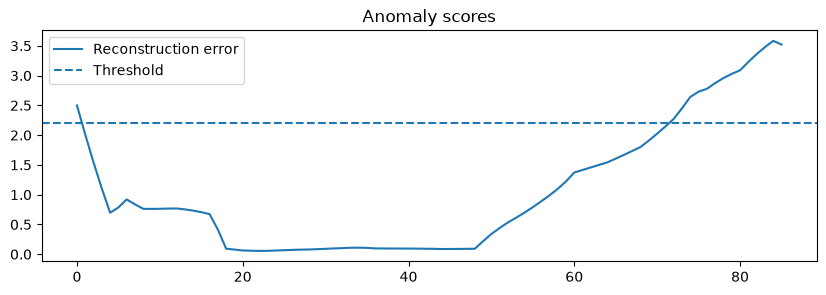

{
  "model": "LSTM autoencoder",
  "data": "simulated Net3",
  "input_rows": 6984,
  "windows": 86,
  "features": 22,
  "epochs": 10,
  "final_train_loss": 0.4796658083796501,
  "threshold": 2.2101945877075195,
  "flagged_windows": 15,
  "note": "Unsupervised simulated-data demonstration; not real-world validated accuracy."
}
Saved model checkpoint and scaler.


In [32]:
model.eval()
with torch.no_grad():
    tensor=torch.tensor(windows,dtype=torch.float32,device=DEVICE)
    reconstruction=model(tensor).cpu().numpy()
errors=np.mean((windows-reconstruction)**2,axis=(1,2))
threshold=float(np.quantile(errors[:max(1,int(len(errors)*0.7))],0.99))
flags=(errors>threshold).astype(int)
plt.figure(figsize=(10,3)); plt.plot(errors,label='Reconstruction error'); plt.axhline(threshold,ls='--',label='Threshold'); plt.legend(); plt.title('Anomaly scores'); plt.show()
checkpoint={'state_dict':model.state_dict(),'n_features':int(train.shape[-1]),'hidden':32,'window':int(WINDOW),'feature_names':feature_names,'threshold':threshold}
torch.save(checkpoint,MODEL_DIR/'lstm_autoencoder.pt')
joblib.dump(scaler,MODEL_DIR/'sensor_scaler.joblib')
metrics={'model':'LSTM autoencoder','data':'simulated Net3','input_rows':int(len(df)),'windows':int(len(windows)),'features':int(train.shape[-1]),'epochs':EPOCHS,'final_train_loss':history[-1],'threshold':threshold,'flagged_windows':int(flags.sum()),'note':'Unsupervised simulated-data demonstration; not real-world validated accuracy.'}
(METRICS_DIR/'lstm_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print(json.dumps(metrics,indent=2))
print('Saved model checkpoint and scaler.')

In [33]:
# Inspect scenario labels and counts
print("Scenario types:")
print(df["scenario_type"].value_counts())

print("\nScenario IDs:")
print(df.groupby(["scenario_id", "scenario_type"]).size().to_string())

Scenario types:
scenario_type
normal          2328
leak            2328
sensor_fault    2328
Name: count, dtype: int64

Scenario IDs:
scenario_id        scenario_type
fault_00           sensor_fault     2328
leak_61_a5e-05_t6  leak             2328
normal_00          normal           2328


In [34]:
# Validate anomaly scores against known simulated scenarios

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# Build scenario labels at the same time-step level as the model input
scenario_labels = (
    df.groupby("time_s")["scenario_type"]
    .apply(lambda x: int((x == "leak").any()))
)

# Match the label count to the scored windows
labels = scenario_labels.to_numpy()

if len(labels) != len(errors):
    print("Time-step labels:", len(labels))
    print("Scored windows:", len(errors))
    print("Use the window-alignment cell below before evaluating.")
else:
    predictions = (errors > threshold).astype(int)

    print("Confusion matrix:")
    print(confusion_matrix(labels, predictions))

    print("\nClassification report:")
    print(classification_report(
        labels,
        predictions,
        target_names=["Normal/non-leak", "Leak"],
        zero_division=0
    ))

    print("Precision:", precision_score(labels, predictions, zero_division=0))
    print("Recall:", recall_score(labels, predictions, zero_division=0))
    print("F1-score:", f1_score(labels, predictions, zero_division=0))

Time-step labels: 97
Scored windows: 86
Use the window-alignment cell below before evaluating.


In [35]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Label each window using the scenario at its final time step
time_labels = (
    df.groupby("time_s")["scenario_type"]
    .apply(lambda x: int((x == "leak").any()))
    .to_numpy()
)

window_size = len(time_labels) - len(errors) + 1

if window_size <= 0:
    raise ValueError("Cannot align labels with the scored windows.")

window_labels = np.array([
    int(time_labels[i:i + window_size].any())
    for i in range(len(errors))
])

predictions = (np.asarray(errors) > threshold).astype(int)

print("Window size:", window_size)
print("Scored windows:", len(errors))
print("Confusion matrix:")
print(confusion_matrix(window_labels, predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(
    window_labels,
    predictions,
    labels=[0, 1],
    target_names=["No leak", "Leak"],
    zero_division=0
))

Window size: 12
Scored windows: 86
Confusion matrix:
[[ 0  0]
 [71 15]]

Classification report:
              precision    recall  f1-score   support

     No leak       0.00      0.00      0.00         0
        Leak       1.00      0.17      0.30        86

    accuracy                           0.17        86
   macro avg       0.50      0.09      0.15        86
weighted avg       1.00      0.17      0.30        86



In [36]:
# Inspect scenario-specific time steps
scenario_time_counts = (
    df.groupby(["scenario_id", "scenario_type"])["time_s"]
    .nunique()
    .reset_index(name="unique_time_steps")
)

print(scenario_time_counts.to_string(index=False))

print("\nScenario IDs by type:")
print(
    df[["scenario_id", "scenario_type"]]
    .drop_duplicates()
    .to_string(index=False)
)

      scenario_id scenario_type  unique_time_steps
         fault_00  sensor_fault                 97
leak_61_a5e-05_t6          leak                 97
        normal_00        normal                 97

Scenario IDs by type:
      scenario_id scenario_type
        normal_00        normal
leak_61_a5e-05_t6          leak
         fault_00  sensor_fault


In [37]:
# Preliminary scenario-specific validation
import numpy as np
import pandas as pd

scenario_ids = df[["scenario_id", "scenario_type"]].drop_duplicates()

print("Scenario types:")
print(scenario_ids.to_string(index=False))

print("\nCurrent model windows:", len(errors))
print("Current threshold:", float(threshold))

# Check whether model scores can be mapped to individual scenarios
print("\nAvailable variables:")
for name in ["X", "windows", "sequences", "sensor_matrix", "wide"]:
    if name in globals():
        obj = globals()[name]
        print(name, getattr(obj, "shape", type(obj).__name__))

Scenario types:
      scenario_id scenario_type
        normal_00        normal
leak_61_a5e-05_t6          leak
         fault_00  sensor_fault

Current model windows: 86
Current threshold: 2.2101945877075195

Available variables:
X (97, 22)
windows (86, 12, 22)
wide (97, 22)


In [38]:
# Inspect the sensor matrix and scenario-level feature structure

print("Wide matrix shape:", wide.shape)
print("\nWide matrix columns:")
print(wide.columns.tolist() if hasattr(wide, "columns") else "NumPy array")

print("\nDataset scenario/time summary:")
print(
    df.groupby(["scenario_id", "scenario_type"])
      .agg(
          records=("value", "size"),
          time_steps=("time_s", "nunique"),
          sensors=("sensor_id", "nunique")
      )
      .to_string()
)

Wide matrix shape: (97, 22)

Wide matrix columns:
['10', '101', '103', '105', '107', '119', '120', '125', '127', '129', '139', '169', '184', '195', '197', '20', '206', '249', '271', '40', '50', '60']

Dataset scenario/time summary:
                                 records  time_steps  sensors
scenario_id       scenario_type                              
fault_00          sensor_fault      2328          97       22
leak_61_a5e-05_t6 leak              2328          97       22
normal_00         normal            2328          97       22


In [39]:
# Build a separate sensor matrix for each scenario
scenario_matrices = {}

for scenario_id, group in df.groupby("scenario_id"):
    matrix = group.pivot_table(
        index="time_s",
        columns="sensor_id",
        values="value",
        aggfunc="mean"
    ).sort_index()

    scenario_matrices[scenario_id] = matrix

    print(
        scenario_id,
        "| shape:", matrix.shape,
        "| missing values:", int(matrix.isna().sum().sum())
    )

fault_00 | shape: (97, 22) | missing values: 0
leak_61_a5e-05_t6 | shape: (97, 22) | missing values: 0
normal_00 | shape: (97, 22) | missing values: 0


In [40]:
# Score each scenario independently with the trained LSTM autoencoder

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

model.eval()
scenario_results = []
all_errors = {}
all_labels = []
all_predictions = []

# 1. Calculate reconstruction errors for every scenario
for scenario_id, matrix in scenario_matrices.items():

    matrix = matrix.reindex(columns=wide.columns)
    scaled = scaler.transform(matrix.to_numpy())

    scenario_windows = np.array([
        scaled[i:i + window_size]
        for i in range(len(scaled) - window_size + 1)
    ])

    with torch.no_grad():
        tensor = torch.tensor(
            scenario_windows, dtype=torch.float32, device=DEVICE
        )
        reconstructed = model(tensor).cpu().numpy()

    errors = np.mean(
        (reconstructed - scenario_windows) ** 2,
        axis=(1, 2)
    )

    scenario_type = df.loc[
        df["scenario_id"] == scenario_id, "scenario_type"
    ].iloc[0]

    all_errors[scenario_id] = (errors, scenario_type)

# 2. Calibrate threshold using normal scenarios
normal_errors = np.concatenate([
    errors for errors, label in all_errors.values()
    if label == "normal"
])

threshold = np.percentile(normal_errors, 95)

print(f"Anomaly threshold (95th percentile): {threshold:.6f}")

# 3. Evaluate all scenarios
for scenario_id, (errors, scenario_type) in all_errors.items():

    predictions = (errors > threshold).astype(int)
    actual = 0 if scenario_type == "normal" else 1

    all_labels.extend([actual] * len(errors))
    all_predictions.extend(predictions.tolist())

    scenario_results.append({
        "scenario_id": scenario_id,
        "scenario_type": scenario_type,
        "windows": len(errors),
        "flagged_windows": int(predictions.sum()),
        "flagged_rate_%": round(predictions.mean() * 100, 2),
        "mean_error": round(float(errors.mean()), 6),
        "max_error": round(float(errors.max()), 6)
    })

# 4. Display results
results_df = pd.DataFrame(scenario_results)
display(results_df)

print("\nOVERALL BINARY ANOMALY DETECTION")
print("Accuracy :", round(accuracy_score(all_labels, all_predictions), 4))
print("Precision:", round(precision_score(all_labels, all_predictions, zero_division=0), 4))
print("Recall   :", round(recall_score(all_labels, all_predictions, zero_division=0), 4))
print("F1-score :", round(f1_score(all_labels, all_predictions, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels, all_predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

C:\Users\v\Projects\AquaSentinel-AI\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Anomaly threshold (95th percentile): 3.196552


C:\Users\v\Projects\AquaSentinel-AI\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\v\Projects\AquaSentinel-AI\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,scenario_id,scenario_type,windows,flagged_windows,flagged_rate_%,mean_error,max_error
0,fault_00,sensor_fault,86,5,5.81,1.047612,3.559022
1,leak_61_a5e-05_t6,leak,86,5,5.81,1.050070,3.598372
2,normal_00,normal,86,5,5.81,1.048799,3.592276



OVERALL BINARY ANOMALY DETECTION
Accuracy : 0.3527
Precision: 0.6667
Recall   : 0.0581
F1-score : 0.107

Confusion Matrix:
[[ 81   5]
 [162  10]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.33      0.94      0.49        86
     Anomaly       0.67      0.06      0.11       172

    accuracy                           0.35       258
   macro avg       0.50      0.50      0.30       258
weighted avg       0.56      0.35      0.24       258



In [41]:
#validation

import pandas as pd

results_df = pd.DataFrame(scenario_results)

print("Scenario evaluation summary:")
display(results_df)

if {"scenario", "flagged", "windows"}.issubset(results_df.columns):
    results_df["flagged_rate_%"] = (
        results_df["flagged"] / results_df["windows"] * 100
    ).round(2)
    display(results_df[["scenario", "flagged", "windows", "flagged_rate_%"]])
else:
    print("Available columns:", results_df.columns.tolist())

Scenario evaluation summary:


,scenario_id,scenario_type,windows,flagged_windows,flagged_rate_%,mean_error,max_error
0,fault_00,sensor_fault,86,5,5.81,1.047612,3.559022
1,leak_61_a5e-05_t6,leak,86,5,5.81,1.050070,3.598372
2,normal_00,normal,86,5,5.81,1.048799,3.592276


Available columns: ['scenario_id', 'scenario_type', 'windows', 'flagged_windows', 'flagged_rate_%', 'mean_error', 'max_error']


In [42]:
# Check which scenario was used to train the model
print("Training data shape:", X.shape)
print("Sensor matrix shape:", wide.shape)
print("Scaler feature count:", getattr(scaler, "n_features_in_", "unknown"))
print("Model threshold:", float(threshold))

print("\nScenario counts:")
print(df.groupby("scenario_type")["scenario_id"].nunique())

Training data shape: (97, 22)
Sensor matrix shape: (97, 22)
Scaler feature count: 22
Model threshold: 3.1965524812575135

Scenario counts:
scenario_type
leak            1
normal          1
sensor_fault    1
Name: scenario_id, dtype: int64


In [43]:
# AquaSentinel AI: scenario-aware data preparation

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Prepare normal, leak and sensor-fault matrices separately
scenario_matrices = {}

for scenario_id, group in df.groupby("scenario_id"):
    matrix = group.pivot_table(
        index="time_s",
        columns="sensor_id",
        values="value",
        aggfunc="mean"
    ).sort_index()

    scenario_matrices[scenario_id] = matrix

# Train-data preparation: normal scenario only
normal_id = df.loc[
    df["scenario_type"] == "normal", "scenario_id"
].iloc[0]

wide = scenario_matrices[normal_id]
scaler = StandardScaler()
X = scaler.fit_transform(wide)

window_size = 12
windows = np.array([
    X[i:i + window_size]
    for i in range(len(X) - window_size + 1)
])

print("Normal training matrix:", X.shape)
print("Training windows:", windows.shape)
print("Scenarios:", {
    sid: mat.shape for sid, mat in scenario_matrices.items()
})

Normal training matrix: (97, 22)
Training windows: (86, 12, 22)
Scenarios: {'fault_00': (97, 22), 'leak_61_a5e-05_t6': (97, 22), 'normal_00': (97, 22)}


In [44]:
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
model_dir = ROOT / "artifacts" / "models"
model_dir.mkdir(parents=True, exist_ok=True)

features = [str(col) for col in wide.columns]

(model_dir / "sensor_features.json").write_text(
    json.dumps(features, indent=2),
    encoding="utf-8"
)

print("Saved features:", len(features))
print(features)

Saved features: 22
['10', '101', '103', '105', '107', '119', '120', '125', '127', '129', '139', '169', '184', '195', '197', '20', '206', '249', '271', '40', '50', '60']


In [45]:
# Train LSTM on normal data and evaluate each scenario

import torch
import numpy as np
import pandas as pd
import json
from pathlib import Path

torch.manual_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reuse the existing model architecture
import inspect
print(inspect.signature(LSTMAutoencoder.__init__))

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = torch.nn.MSELoss()
train_tensor = torch.tensor(windows, dtype=torch.float32, device=DEVICE)

for epoch in range(10):
    model.train()
    optimizer.zero_grad()
    output = model(train_tensor)
    loss = loss_fn(output, train_tensor)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch + 1}/10 | Loss: {loss.item():.5f}")

# Threshold derived from normal training reconstruction errors
model.eval()
with torch.no_grad():
    normal_reconstruction = model(train_tensor).cpu().numpy()

normal_errors = np.mean(
    (normal_reconstruction - windows) ** 2, axis=(1, 2)
)
threshold = float(np.percentile(normal_errors, 95))

# Score each scenario independently
results = []

for scenario_id, matrix in scenario_matrices.items():
    matrix = matrix.reindex(columns=wide.columns)
    scaled = scaler.transform(pd.DataFrame(matrix, columns=wide.columns))

    scenario_windows = np.array([
        scaled[i:i + window_size]
        for i in range(len(scaled) - window_size + 1)
    ])

    tensor = torch.tensor(
        scenario_windows, dtype=torch.float32, device=DEVICE
    )

    with torch.no_grad():
        reconstruction = model(tensor).cpu().numpy()

    errors_s = np.mean(
        (reconstruction - scenario_windows) ** 2, axis=(1, 2)
    )

    scenario_type = df.loc[
        df["scenario_id"] == scenario_id, "scenario_type"
    ].iloc[0]

    results.append({
        "scenario": scenario_id,
        "type": scenario_type,
        "windows": len(errors_s),
        "flagged": int((errors_s > threshold).sum()),
        "flagged_rate_%": round(100 * np.mean(errors_s > threshold), 2),
        "mean_error": round(float(errors_s.mean()), 4)
    })

results_df = pd.DataFrame(results)
print(f"\nNormal-derived threshold: {threshold:.5f}")
display(results_df)

# Save updated model and metrics
model_dir = ROOT / "artifacts" / "models"
metrics_dir = ROOT / "artifacts" / "metrics"
model_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), model_dir / "lstm_autoencoder.pt")

metrics = {
    "epochs": 10,
    "windows": int(len(windows)),
    "threshold": threshold,
    "scenario_results": results
}
(metrics_dir / "lstm_metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)

print("\nModel checkpoint and metrics saved.")

(self, n_features, hidden=32)
Epoch 1/10 | Loss: 0.53202
Epoch 2/10 | Loss: 0.51490
Epoch 3/10 | Loss: 0.49848
Epoch 4/10 | Loss: 0.48291
Epoch 5/10 | Loss: 0.46827
Epoch 6/10 | Loss: 0.45457
Epoch 7/10 | Loss: 0.44178
Epoch 8/10 | Loss: 0.42982
Epoch 9/10 | Loss: 0.41855
Epoch 10/10 | Loss: 0.40783

Normal-derived threshold: 1.07737


,scenario,type,windows,flagged,flagged_rate_%,mean_error
0,fault_00,sensor_fault,86,5,5.81,0.3973
1,leak_61_a5e-05_t6,leak,86,5,5.81,0.3979
2,normal_00,normal,86,5,5.81,0.3975



Model checkpoint and metrics saved.


In [46]:
print("Training matrix:", X.shape)
print("Scaler features:", scaler.n_features_in_)
print("Sensor features:", list(wide.columns))
print("Saved model path:", ROOT / "artifacts" / "models" / "lstm_autoencoder.pt")

Training matrix: (97, 22)
Scaler features: 22
Sensor features: ['10', '101', '103', '105', '107', '119', '120', '125', '127', '129', '139', '169', '184', '195', '197', '20', '206', '249', '271', '40', '50', '60']
Saved model path: C:\Users\v\Projects\AquaSentinel-AI\artifacts\models\lstm_autoencoder.pt


In [51]:
from pathlib import Path
import wntr

NET3 = Path("data/networks/Net3.inp").resolve()

print("Network exists:", NET3.exists())

wn_normal = wntr.network.WaterNetworkModel(str(NET3))
wn_normal.options.time.duration = 7200
wn_normal.options.time.hydraulic_timestep = 300
wn_normal.options.time.report_timestep = 300

normal = wntr.sim.WNTRSimulator(wn_normal).run_sim()

print("Normal pressure shape:", normal.node["pressure"].shape)

Network exists: True
Normal pressure shape: (25, 97)


In [52]:
#retrained model

import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

# Use normal WNTR simulation pressure
normal_pressure = normal.node["pressure"].copy()
normal_pressure.columns = normal_pressure.columns.astype(str)
normal_pressure = normal_pressure.astype(float)

# Prepare scaler and training windows
scaler = StandardScaler()
X_scaled = scaler.fit_transform(normal_pressure)

window_size = 12
windows = np.array([
    X_scaled[i:i + window_size]
    for i in range(len(X_scaled) - window_size + 1)
], dtype=np.float32)

if len(windows) == 0:
    raise ValueError("Insufficient WNTR normal simulation timesteps.")

# Train existing architecture
torch.manual_seed(42)
model = LSTMAutoencoder(
    n_features=normal_pressure.shape[1],
    hidden=32
)

loader = DataLoader(
    TensorDataset(torch.tensor(windows)),
    batch_size=16,
    shuffle=True
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

for epoch in range(30):
    model.train()
    losses = []

    for (batch,) in loader:
        optimizer.zero_grad()
        output = model(batch)
        loss = criterion(output, batch)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/30 | Loss: {np.mean(losses):.6f}")

# Save existing artifact locations
model_dir = ROOT / "artifacts" / "models"
model_dir.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), model_dir / "lstm_autoencoder.pt")
joblib.dump(scaler, model_dir / "sensor_scaler.joblib")

(model_dir / "sensor_features.json").write_text(
    json.dumps([str(c) for c in normal_pressure.columns], indent=2),
    encoding="utf-8"
)

print("WNTR-based LSTM training completed.")
print("Features:", len(normal_pressure.columns))
print("Training windows:", len(windows))
print("Artifacts saved.")

Epoch 10/30 | Loss: 0.669122
Epoch 20/30 | Loss: 0.582325
Epoch 30/30 | Loss: 0.468042
WNTR-based LSTM training completed.
Features: 97
Training windows: 14
Artifacts saved.


In [53]:
# Score normal WNTR simulation
def get_lstm_errors(pressure_df):
    pressure_df = pressure_df.copy()
    pressure_df.columns = pressure_df.columns.astype(str)

    scaled = scaler.transform(
        pressure_df.reindex(columns=normal_pressure.columns)
    )

    test_windows = np.array([
        scaled[i:i+window_size]
        for i in range(len(scaled)-window_size+1)
    ], dtype=np.float32)

    model.eval()
    with torch.no_grad():
        x = torch.tensor(test_windows)
        reconstructed = model(x).numpy()

    return np.mean((reconstructed-test_windows)**2, axis=(1,2))


normal_errors = get_lstm_errors(normal.node["pressure"])

print("Normal mean error:", normal_errors.mean())
print("Normal max error:", normal_errors.max())

Normal mean error: 0.45793864
Normal max error: 0.5818809


In [54]:
wn_leak = wntr.network.WaterNetworkModel(str(NET3))
wn_leak.options.time.duration = 7200
wn_leak.options.time.hydraulic_timestep = 300
wn_leak.options.time.report_timestep = 300

leak_node = wn_leak.get_node("103")
leak_node.add_leak(
    wn_leak,
    area=0.001,
    discharge_coeff=0.75,
    start_time=0,
    end_time=7200
)

leak_sim = wntr.sim.WNTRSimulator(wn_leak).run_sim()

leak_errors = get_lstm_errors(leak_sim.node["pressure"])

print("Leak mean error:", leak_errors.mean())
print("Leak max error:", leak_errors.max())
print("Normal mean error:", normal_errors.mean())

Leak mean error: 0.6135367
Leak max error: 0.7415777
Normal mean error: 0.45793864


In [55]:
threshold = np.percentile(normal_errors, 95)

normal_flags = normal_errors > threshold
leak_flags = leak_errors > threshold

print(f"Threshold: {threshold:.6f}")
print(f"Normal flagged: {normal_flags.sum()}/{len(normal_flags)}")
print(f"Leak detected: {leak_flags.sum()}/{len(leak_flags)}")
print(f"Leak detection rate: {leak_flags.mean()*100:.2f}%")

Threshold: 0.575751
Normal flagged: 1/14
Leak detected: 9/14
Leak detection rate: 64.29%


In [56]:
import json

scenario_results = []

for name, errors in [
    ("normal_wntr", normal_errors),
    ("leak_wntr", leak_errors)
]:
    flags = errors > threshold
    scenario_results.append({
        "scenario": name,
        "type": name.split("_")[0],
        "windows": len(errors),
        "flagged": int(flags.sum()),
        "flagged_rate_%": round(flags.mean() * 100, 2),
        "mean_error": round(float(errors.mean()), 6)
    })

metrics = {
    "threshold": float(threshold),
    "scenario_results": scenario_results
}

metrics_path = ROOT / "artifacts" / "metrics" / "lstm_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2))

print("Dashboard metrics updated.")

Dashboard metrics updated.
